# Dynamic Characterization of Two-Degree-of-Freedom Equipment-Structure Systems: the Equipment Response under White Noise

__Takeru Igusa__, Department of Civil Engineering, University of California, Berkeley, Calif.

__Armen Der Kiureghian__, Department of Civil Engineering, University of California, Berkeley, Calif.

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import oscillator_model as om

SEED = 1985                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels7 = [r'$m_p$', r'$m_s$', r'$k_p$', r'$k_s$', r'$\zeta_p$', r'$\zeta_s$', r'$S_0$']
labels8 = labels7 + [r'$F_s$']

### Summary

Igusa and Der Kiureghian [[1]][R1] derive, by perturbation theory, a closed-form expression (their Eq. 37) for the mean-square response of a light piece of equipment (a secondary oscillator) mounted on a structure (a primary oscillator) whose base is shaken by white noise; the expression captures tuning of the two frequencies, interaction through the mass ratio, and nonclassical damping. We give its seven inputs (two masses, two stiffnesses, two damping ratios and the noise intensity) the independent lognormal distributions of the reliability benchmark built on this model by Der Kiureghian and De Stefano [[2]][R2] (as given by OpenTURNS [[4]][R4]), and compute the active subspace of the RMS deformation of the equipment spring, and of the benchmark's limit-state function $G = F_s - 3k_s\,\mathrm{RMS}$, with respect to the logarithms of the inputs, from 1000 samples with exact gradients. The RMS response has a two-dimensional active subspace whose first direction is almost exactly the detuning $\ln(\omega_p/\omega_s)$ and whose second is mainly the two damping ratios, so a sufficient summary plot recovers the tuning resonance of the paper's Fig. 5.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

A structure (primary oscillator: mass $m_p$, frequency $\omega_p$, damping ratio $\zeta_p$) carries a piece of equipment (secondary oscillator: $m_s$, $\omega_s$, $\zeta_s$), and the base is shaken by stationary white-noise acceleration with one-sided power spectral density $G_0$ [[1]][R1] (Fig. 1 and Eq. 1, pp. 2–3). The paper's characteristic parameters are (Eqs. 2a, 2b, 2d, 3a)

$$
\beta = \frac{\omega_p-\omega_s}{\omega_a}\ \text{(tuning)},\qquad \gamma = \frac{m_s}{m_p}\ \text{(interaction)},\qquad \omega_a = \frac{\omega_p+\omega_s}{2},\qquad \zeta_a = \frac{\zeta_p+\zeta_s}{2},
$$

and the general ("matched") expression for the mean-square response of the equipment, valid for all $\beta$, is Eq. 37 (p. 12):

$$
E[x_s^2] = \frac{\pi G_0}{4\zeta_s\omega_s^3}\left[\frac{\zeta_a\zeta_s}{\zeta_p\zeta_s(4\zeta_a^2+\beta^2)+\gamma\zeta_a^2}\;\frac{(\zeta_p\omega_p^3+\zeta_s\omega_s^3)\,\omega_p}{4\zeta_a\omega_a^4}\right].
$$

The first factor is the response of the equipment alone on the shaking base; the bracket is an amplification factor, largest at perfect tuning $\beta = 0$ and limited there by damping and by the mass ratio $\gamma$. The benchmark [[2]][R2][[4]][R4] uses exactly this formula, with $\omega_p = \sqrt{k_p/m_p}$, $\omega_s = \sqrt{k_s/m_s}$, $S_0$ for $G_0$ and $\theta$ for $\beta$ (we checked it term by term against the page image of Eq. 37; `oscillator_model.mean_square` cancels the common $\zeta_a$ and agrees with the printed form to rounding).

**Which displacement.** The paper writes the equations of motion (Eq. 1) in displacements relative to the ground, but Eq. 37 is the mean square of the equipment's displacement relative to the primary mass, i.e. the deformation of the secondary spring: an exact (Lyapunov) solution of the 2-DOF system agrees with Eq. 37 for the spring deformation and not for the equipment's displacement relative to the ground (checked below against the paper's Fig. 5). This is also how the benchmark uses it: $k_s\sqrt{E[x_s^2]}$ is the RMS force in the secondary spring.

**Quantities of interest.** (a) $\mathrm{RMS} = \sqrt{E[x_s^2]}$, a function of the seven inputs $m_p, m_s, k_p, k_s, \zeta_p, \zeta_s, S_0$. (b) The limit state of the reliability benchmark [[2]][R2][[4]][R4], $G = F_s - 3\,k_s\,\mathrm{RMS}$, with the spring's force capacity $F_s$ as an eighth input; failure is $G \le 0$. Units are not given by the benchmark; any consistent set (the mean $\omega_s$ is 1 rad per unit time).

**Inputs and the transform.** The 1985 paper has no probabilistic study. The distributions are those of the benchmark [[2]][R2], as given by the OpenTURNS oscillator use case [[4]][R4] (which also cites Dubourg et al. [[3]][R3]; UQTestFuns [[5]][R5] gives the same seven for the RMS): all eight inputs independent and lognormal, given by mean and coefficient of variation, so $\ln x_i \sim N(\mu_i, \sigma_i^2)$ with $\sigma_i = \sqrt{\ln(1+\mathrm{CoV}_i^2)}$ and $\mu_i = \ln(\text{mean}_i) - \sigma_i^2/2$. The library's input spaces are uniform or Gaussian, so we work in the log inputs $\mathbf z = \ln\mathbf x$, which are exactly Gaussian, and normalize every input the same way, $x^{\mathrm{norm}}_i = (z_i - \mu_i)/\sigma_i$. The files hold the physical inputs; the conversion $\mathbf Z = \ln\mathbf X$ is done once, in the load cell. The gradients in the files are with respect to $\mathbf z$, $\partial f/\partial z_i = x_i\,\partial f/\partial x_i$, exact (chain rule through $\omega_p, \omega_s, \omega_a, \zeta_a, \beta, \gamma$).

The cell prints the input table from `oscillator_model.py`, and the mean-square response at the input means.

In [2]:
print(f"{'input':8s} {'mean':>8s} {'CoV':>5s} {'mu':>9s} {'sigma':>8s}  description")
for j, n in enumerate(om.NAMES):
    print(f'{n:8s} {om.MEAN[j]:8.4g} {om.COV[j]:5.2f} {om.MU[j]:9.5f} {om.SIGMA[j]:8.6f}  {om.DESCRIPTIONS[j]}')
x_mean = om.MEAN
wp, ws = np.sqrt(x_mean[2] / x_mean[0]), np.sqrt(x_mean[3] / x_mean[1])
print(f'\nat the input means: omega_p = {wp:.4f}, omega_s = {ws:.4f}, beta = {(wp - ws) / ((wp + ws) / 2):.4f}, '
      f'gamma = {x_mean[1] / x_mean[0]:.5f}; E[x_s^2] = {om.mean_square(x_mean)[0]:.2f}, '
      f'RMS = {om.rms(x_mean)[0]:.3f}, G = {om.limit_state(x_mean)[0]:.3f}')
print(f'Eq. 37 as printed vs the cancelled form used in the module, at the means: '
      f'relative difference {abs(om.mean_square_as_printed(x_mean)[0] / om.mean_square(x_mean)[0] - 1):.1e}')

input        mean   CoV        mu    sigma  description
mp            1.5  0.10   0.40049 0.099751  primary (structure) mass
ms           0.01  0.10  -4.61015 0.099751  secondary (equipment) mass
kp              1  0.20  -0.01961 0.198042  primary spring stiffness
ks           0.01  0.20  -4.62478 0.198042  secondary spring stiffness
zeta_p       0.05  0.40  -3.06994 0.385253  primary damping ratio
zeta_s       0.02  0.50  -4.02359 0.472381  secondary damping ratio
S0            100  0.10   4.60020 0.099751  white-noise base acceleration intensity (one-sided PSD, the paper's G0)
Fs           27.5  0.10   3.30921 0.099751  force capacity of the secondary spring

at the input means: omega_p = 0.8165, omega_s = 1.0000, beta = -0.2020, gamma = 0.00667; E[x_s^2] = 20643.07, RMS = 143.677, G = 23.190
Eq. 37 as printed vs the cancelled form used in the module, at the means: relative difference 0.0e+00


### Load data

`generate_data.py` drew $M = 1000$ Monte Carlo samples of the eight inputs (seed 1985) and wrote the physical inputs, the outputs (RMS from Eq. 37, $G$, and the exact RMS deformation from a Lyapunov solve, used only for the accuracy check), and the exact gradients of RMS and $G$ with respect to $\mathbf z = \ln\mathbf x$ (see `DATA.md`). This cell also makes the one conversion to log coordinates.

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')        # (M, 8) physical inputs mp, ms, kp, ks, zeta_p, zeta_s, S0, Fs
F = np.loadtxt('outputs.csv', delimiter=',')       # (M, 3) rms (Eq. 37), G, rms_exact (Lyapunov)
D = np.loadtxt('gradients.csv', delimiter=',')     # (M, 15) d rms/d ln x (7 columns), dG/d ln x (8 columns)
Z = np.log(X)                                      # log inputs: the coordinates of the analysis
rms, G, rms_exact = F.T
d_rms, d_G = D[:, :7], D[:, 7:]
print(f'inputs {X.shape}, outputs {F.shape}, gradients {D.shape}')

inputs (1000, 8), outputs (1000, 3), gradients (1000, 15)


We check the files against the model and the gradients against central finite differences in $\mathbf z$ (step $10^{-6}$), check that the log inputs have the declared normal marginals, and look at the sampled range of the perturbation parameters.

In [4]:
h = 1e-6
fd_rms = np.column_stack([(om.rms(np.exp(Z + h*e)) - om.rms(np.exp(Z - h*e))) / (2*h) for e in np.eye(8)[:7]])
fd_G = np.column_stack([(om.limit_state(np.exp(Z + h*e)) - om.limit_state(np.exp(Z - h*e))) / (2*h) for e in np.eye(8)])
print(f'max |model - file| / |file|: rms {np.max(np.abs(om.rms(X) / rms - 1)):.1e}, '
      f'G {np.max(np.abs(om.limit_state(X) / G - 1)):.1e}')
print(f'gradients vs central differences, max relative error (row 2-norm): '
      f'rms {np.max(np.linalg.norm(fd_rms - d_rms, axis=1) / np.linalg.norm(d_rms, axis=1)):.1e}, '
      f'G {np.max(np.linalg.norm(fd_G - d_G, axis=1) / np.linalg.norm(d_G, axis=1)):.1e}')
U = (Z - om.MU) / om.SIGMA
kurt = np.mean(U**4, axis=0) / np.mean(U**2, axis=0)**2
print('normalized log inputs: means', np.round(U.mean(axis=0), 3), '\n  standard deviations', np.round(U.std(axis=0, ddof=1), 3),
      '\n  kurtosis', np.round(kurt, 2), f'; duplicate rows: {len(X) - len(np.unique(X, axis=0))}')
from scipy.stats import kstest
print('Kolmogorov-Smirnov p-values of the normalized log inputs against N(0, 1):',
      np.round([kstest(U[:, j], 'norm').pvalue for j in range(8)], 3))
se_k = np.sqrt(24 / len(U))                                         # standard error of the kurtosis of a normal sample
j_k = np.argmax(kurt); i_k = np.argmax(np.abs(U[:, j_k]))
k_sim = []
rng_k = np.random.default_rng(SEED)
for _ in range(10):                                                 # 5000 normal samples of size 1000 x 8, in blocks
    S = rng_k.standard_normal((500, len(U), 8))
    k_sim.append((np.mean(S**4, axis=1) / np.mean(S**2, axis=1)**2).max(axis=1))
k_sim = np.concatenate(k_sim)
print(f'largest kurtosis {kurt[j_k]:.2f} ({om.NAMES[j_k]}) = 3 + {(kurt[j_k] - 3) / se_k:.1f} standard errors (sqrt(24/M) = {se_k:.3f}); '
      f'its most extreme normalized value {U[i_k, j_k]:+.2f}, kurtosis without that sample '
      f'{np.mean(np.delete(U[:, j_k], i_k)**4) / np.mean(np.delete(U[:, j_k], i_k)**2)**2:.2f}; '
      f'largest of 8 kurtoses >= {kurt[j_k]:.2f} in {100 * np.mean(k_sim >= kurt[j_k]):.2f} % of {len(k_sim)} simulated N(0, 1) samples')
wp, ws = np.sqrt(X[:, 2] / X[:, 0]), np.sqrt(X[:, 3] / X[:, 1])
beta = (wp - ws) / ((wp + ws) / 2)
print(f'sampled ranges: beta [{beta.min():.3f}, {beta.max():.3f}], gamma [{(X[:, 1] / X[:, 0]).min():.4f}, '
      f'{(X[:, 1] / X[:, 0]).max():.4f}], zeta_p [{X[:, 4].min():.4f}, {X[:, 4].max():.4f}], '
      f'zeta_s [{X[:, 5].min():.4f}, {X[:, 5].max():.4f}]; samples with zeta >= 1: {(X[:, 4:6] >= 1).any(axis=1).sum()}')
print(f'samples with |beta| < 0.05 (near tuning): {(np.abs(beta) < 0.05).sum()}; '
      f'samples with G <= 0 (failure): {(G <= 0).sum()}; min G = {G.min():.3f}')
print(f'RMS: sample mean {rms.mean():.2f}, variance {rms.var(ddof=1):.0f}, '
      f'2.5/50/97.5 percentiles {np.percentile(rms, [2.5, 50, 97.5]).round(1).tolist()}')

max |model - file| / |file|: rms 0.0e+00, G 0.0e+00
gradients vs central differences, max relative error (row 2-norm): rms 4.3e-10, G 2.7e-10
normalized log inputs: means [-0.006 -0.009 -0.046 -0.014 -0.016 -0.002  0.003  0.024] 
  standard deviations [0.975 1.02  1.015 1.024 0.992 0.995 1.034 0.98 ] 
  kurtosis [3.11 2.89 3.07 3.2  3.64 2.92 2.9  2.73] ; duplicate rows: 0
Kolmogorov-Smirnov p-values of the normalized log inputs against N(0, 1): [0.96  0.611 0.047 0.345 0.642 0.884 0.578 0.463]


largest kurtosis 3.64 (zeta_p) = 3 + 4.1 standard errors (sqrt(24/M) = 0.155); its most extreme normalized value -4.21, kurtosis without that sample 3.43; largest of 8 kurtoses >= 3.64 in 0.46 % of 5000 simulated N(0, 1) samples
sampled ranges: beta [-0.686, 0.260], gamma [0.0046, 0.0110], zeta_p [0.0092, 0.2239], zeta_s [0.0040, 0.0677]; samples with zeta >= 1: 0
samples with |beta| < 0.05 (near tuning): 111; samples with G <= 0 (failure): 0; min G = 7.293
RMS: sample mean 189.09, variance 15697, 2.5/50/97.5 percentiles [44.5, 149.8, 520.1]


The files match the model exactly, and the gradients agree with central differences to $4.3\times10^{-10}$ (RMS) and $2.7\times10^{-10}$ ($G$), the size of the differencing error. The normalized log inputs have means within 0.05 of 0 and standard deviations within 0.035 of 1; Kolmogorov–Smirnov tests against $N(0,1)$ give p-values 0.047–0.96 over the eight inputs (the smallest, for $k_p$, is unremarkable among eight tests). The kurtoses are 2.73–3.64. The largest, 3.64 for $\zeta_p$, is 4.1 standard errors above the normal value 3, and only 0.46 % of 5000 simulated normal samples of the same size (1000 × 8) have a largest kurtosis that high, so it is a rare draw. It comes from the tails: one draw at $-4.21$ standard deviations (the smallest $\zeta_p$, 0.0092), and the kurtosis is 3.43 without it. It is not an error in the transform: the inputs are $\exp(\mu_i + \sigma_i\xi_i)$ of the generator's standard normal draws, and the $\zeta_p$ KS p-value is 0.642. It is a property of this seed-1985 sample, which we keep. There are no duplicate rows. Every input is positive by construction, and no damping ratio reaches 1 (the largest $\zeta_p$ is 0.224); but the perturbation theory assumes small damping and small $\gamma$, and its error at large $\zeta_p$ is measured in the accuracy section below. The tuning parameter spans $[-0.686, 0.260]$, with 111 samples within 0.05 of perfect tuning. No sample fails ($G > 0$ everywhere, smallest 7.293), as expected for $P_f \approx 4\times10^{-7}$.

### Estimate the subspace

The model is closed-form, so we have exact gradients and use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i\nabla f_i^T$ in normalized coordinates; $M = 1000$ is above $10m$ and 300. The input space is `ac.Gaussian` with mean $\boldsymbol\mu$ and variances $\boldsymbol\sigma^2$ on the **log** inputs; we pass $\mathbf Z$ and the gradients with respect to $\mathbf z$, and the library maps both to normalized coordinates once (the normalized gradient is $\sigma_i\,\partial f/\partial z_i$). We use 500 bootstrap replicates, and we orient each eigenvector so that its active variable has a nonnegative sample covariance with the QoI (`ac.orient(by="covariance")`).

**Dimension.** We set $n = 2$ by hand. The library's eigenvalue-gap rule (`"evg"`, which is `EVG(gap="linear")`) measures absolute gaps and picks $n = 1$. Its log-gap variant, `EVG(gap="log")`, picks $k = 5$, because the largest log gap is the one down to the two exact null eigenvalues explained below (both choices are printed). So neither built-in variant compares the ratios among the nonzero eigenvalues, and we choose by hand: on the log scale on which eigenvalues are compared, the gap after $\lambda_2$ is larger than the gap after $\lambda_1$ (both ratios are printed below), the bootstrap subspace error at $k = 2$ is small, and the second direction has a clear physical meaning (damping, see below).

Two eigenvalues are exactly zero for a structural reason: $E[x_s^2]$ depends on the masses and stiffnesses only through $\omega_p$, $\omega_s$ and $\gamma$, so scaling all four by the same factor leaves it unchanged; and it is $S_0$ times a function of the frequencies that is homogeneous of degree $-3$, so scaling $\omega_p$ and $\omega_s$ by $c$ and $S_0$ by $c^3$ leaves it unchanged. Both are straight lines in $\mathbf z$, so they are exact null directions of $\mathbf C$.

In [5]:
space7 = ac.Gaussian(om.MU[:7], om.SIGMA[:7]**2, names=[f'ln {n}' for n in om.NAMES[:7]])
sub = ac.active_subspace(space=space7, X=Z[:, :7], f=rms, grads=d_rms, estimator='as', n=2, nboot=500, rng=SEED)
sub = ac.orient(sub, by='covariance', X=Z[:, :7], f=rms)
lam = sub.eigenvalues
_, _, k_evg = ac.dimension_criterion(sub, rule='evg')
from active_subspaces.subspaces import EVG
_, _, k_evg_log = ac.dimension_criterion(sub, rule=EVG(gap='log'))
print('eigenvalues:', np.array2string(lam, precision=4))
print(f'n = {sub.n} (set by hand; the library "evg" rule picks {k_evg}, its log-gap variant EVG(gap="log") picks {k_evg_log}); '
      f'lambda_1/lambda_2 = {lam[0] / lam[1]:.1f}, lambda_2/lambda_3 = {lam[1] / lam[2]:.1f}, '
      f'lambda_3/lambda_4 = {lam[2] / lam[3]:.2f}; share of the trace in the first two: {lam[:2].sum() / lam.sum():.4f}')

eigenvalues: [2.1397e+04 1.7680e+03 6.0066e+01 1.4919e+01 4.8098e+00 3.1655e-28
 2.9174e-29]
n = 2 (set by hand; the library "evg" rule picks 1, its log-gap variant EVG(gap="log") picks 5); lambda_1/lambda_2 = 12.1, lambda_2/lambda_3 = 29.4, lambda_3/lambda_4 = 4.03; share of the trace in the first two: 0.9966


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

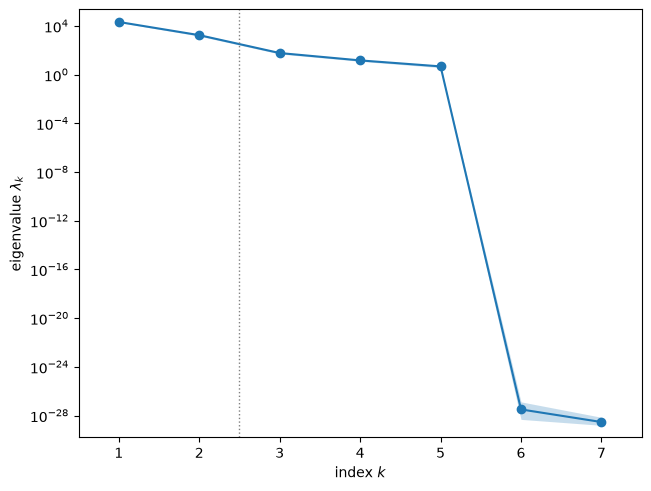

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
fig

The eigenvalues are $\lambda_1 = 2.140\times10^4$, $\lambda_2 = 1768$, $\lambda_3 = 60.1$, $\lambda_4 = 14.9$ and $\lambda_5 = 4.81$, so $\lambda_1/\lambda_2 = 12.1$ and $\lambda_2/\lambda_3 = 29.4$ (then $\lambda_3/\lambda_4 = 4.03$), and the first two hold 99.66 % of the trace. $\lambda_6$ and $\lambda_7$ ($3.2\times10^{-28}$ and $2.9\times10^{-29}$) are rounding errors: they are the two exact null directions explained above. The largest ratio, $\lambda_2/\lambda_3$, is the reason for $n = 2$.

bootstrap mean subspace distance, k = 1..6: [7.943e-03 1.325e-02 3.842e-02 4.107e-02 1.035e-15 6.750e-01]


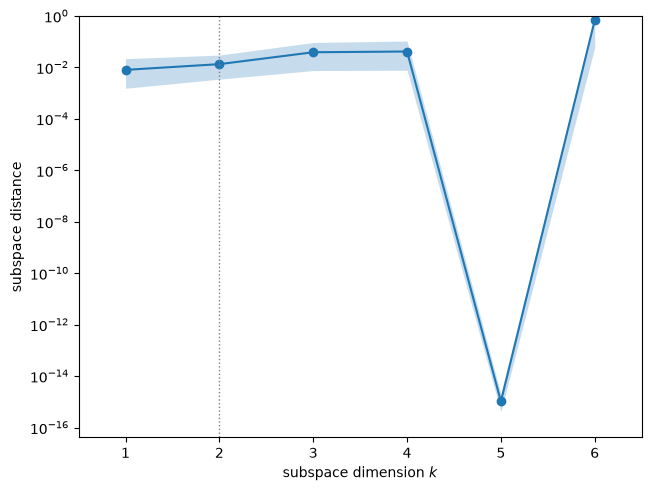

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..6:', np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean subspace distance is $7.9\times10^{-3}$ for $k = 1$ and $1.3\times10^{-2}$ for $k = 2$, so both the first direction and the first two are estimated stably from 1000 samples; it is 0.038 and 0.041 for $k = 3, 4$. At $k = 5$ it is $1.0\times10^{-15}$ because that subspace is the complement of the two exact null directions, and at $k = 6$ (0.675) it splits the null space arbitrarily.

w1: mp -0.250, ms +0.332, kp +0.538, ks -0.700, zeta_p -0.163, zeta_s -0.138, S0 +0.055
w2: mp +0.310, ms -0.027, kp -0.398, ks -0.162, zeta_p -0.609, zeta_s -0.558, S0 +0.188
|w1 . t| = 0.9665, |w2 . t| = 0.2560, with t the normalized direction of ln(omega_p/omega_s); share of w2^2 on (zeta_p, zeta_s): 0.683


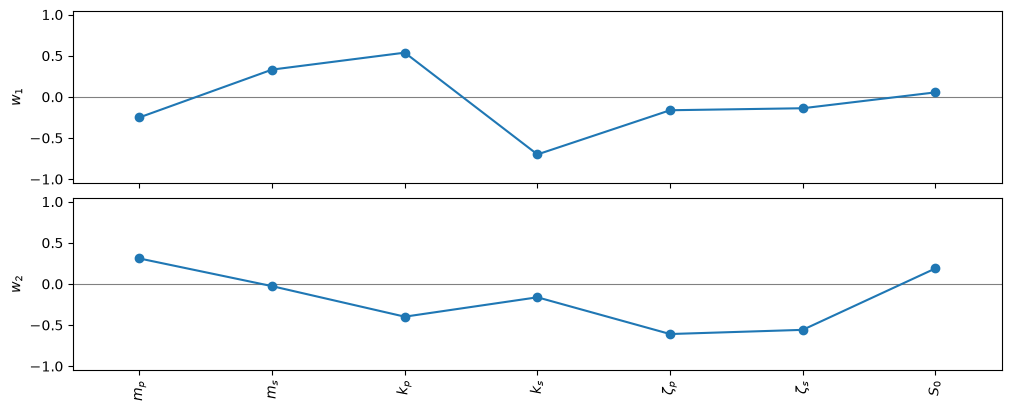

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=labels7, figsize=(10, 4))
plt.close(fig)
W = sub.W
t = om.SIGMA[:7] * np.array([-1, 1, 1, -1, 0, 0, 0]) / 2       # sigma-scaled gradient of ln(omega_p/omega_s)
t /= np.linalg.norm(t)
for k in (0, 1):
    print(f'w{k + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(om.NAMES, W[:, k])))
print(f'|w1 . t| = {abs(W[:, 0] @ t):.4f}, |w2 . t| = {abs(W[:, 1] @ t):.4f}, '
      f'with t the normalized direction of ln(omega_p/omega_s); share of w2^2 on (zeta_p, zeta_s): {np.sum(W[4:6, 1]**2):.3f}')
fig

The first eigenvector is $\mathbf w_1 = (-0.250, +0.332, +0.538, -0.700, -0.163, -0.138, +0.055)$ in the order $m_p, m_s, k_p, k_s, \zeta_p, \zeta_s, S_0$: its large weights are on the masses and stiffnesses, with the signs of $\ln(\omega_p/\omega_s) = \tfrac12(\ln k_p - \ln m_p - \ln k_s + \ln m_s)$, and $|\mathbf w_1\cdot\mathbf t| = 0.9665$, where $\mathbf t$ is the normalized direction of that detuning. At the input means $\omega_p = 0.8165 < \omega_s = 1$ ($\beta = -0.20$), so moving along $+\mathbf w_1$ brings the two oscillators toward tuning. $k_s$ outweighs $k_p$ ($-0.700$ against $+0.538$) because a softer equipment spring both tunes the system and raises the prefactor $\pi S_0/(4\zeta_s\omega_s^3)$. The second eigenvector is mostly damping: $\zeta_p$ ($-0.609$) and $\zeta_s$ ($-0.558$) carry 68.3 % of $\|\mathbf w_2\|^2$, with $k_p$ ($-0.398$) and $m_p$ ($+0.310$) next; its overlap with the detuning direction is 0.256. So the two active variables are, approximately, how well the oscillators are tuned and how little they are damped.

y1 range [-3.33, 3.31]; corr(y1, ln(omega_p/omega_s)) = 0.9697; RMS is largest at y1 = 1.95 (beta there 0.012)


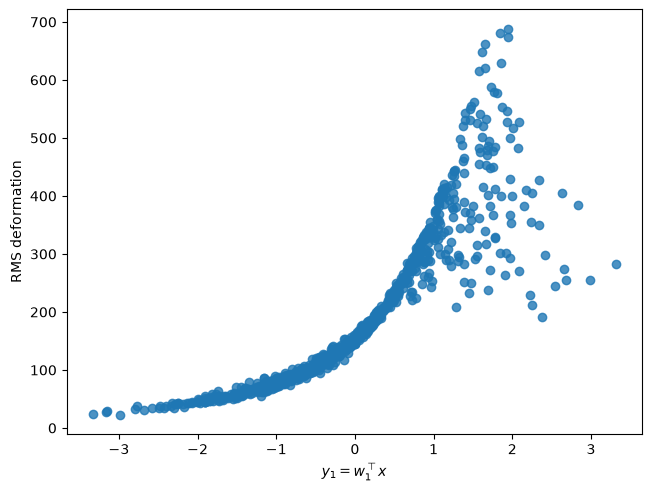

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Z[:, :7], f=rms, dims=1, qoi_label='RMS deformation')
plt.close(fig)
Y = space7.to_normalized(Z[:, :7]) @ W[:, :2]
print(f'y1 range [{Y[:, 0].min():.2f}, {Y[:, 0].max():.2f}]; corr(y1, ln(omega_p/omega_s)) = '
      f'{np.corrcoef(Y[:, 0], np.log(wp / ws))[0, 1]:.4f}; RMS is largest at y1 = {Y[np.argmax(rms), 0]:.2f} '
      f'(beta there {beta[np.argmax(rms)]:.3f})')
fig

samples with y1 > 1: 163; correlation of RMS with y2 among them 0.789, among the samples with y1 < 0: 0.124


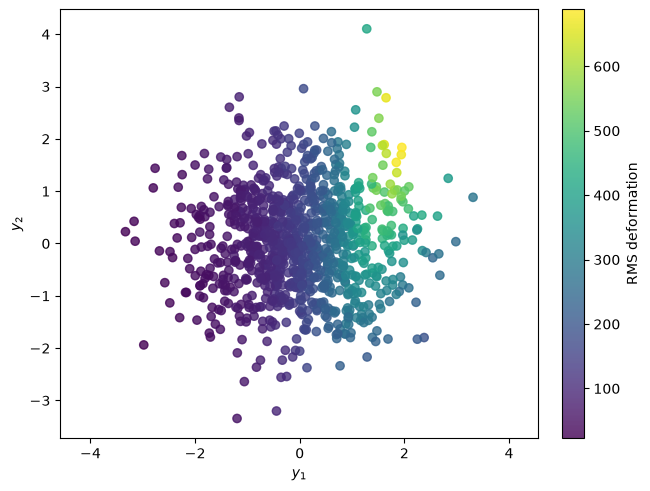

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=Z[:, :7], f=rms, dims=2, qoi_label='RMS deformation')
plt.close(fig)
near = Y[:, 0] > 1
print(f'samples with y1 > 1: {near.sum()}; correlation of RMS with y2 among them {np.corrcoef(Y[near, 1], rms[near])[0, 1]:.3f}, '
      f'among the samples with y1 < 0: {np.corrcoef(Y[Y[:, 0] < 0, 1], rms[Y[:, 0] < 0])[0, 1]:.3f}')
fig

The active variable $y_1$ ranges over $[-3.33, 3.31]$ and has correlation 0.9697 with $\ln(\omega_p/\omega_s)$. Against $y_1$ the RMS deformation rises steadily to its maximum at $y_1 = 1.95$, where $\beta = 0.012$, i.e. at tuning, and falls again with more scatter beyond it, where the structure is stiffer than the equipment: the tuning resonance of the paper's Fig. 5, seen in a random sample of all seven inputs. The two-dimensional plot shows the second variable at work near the peak: among the 163 samples with $y_1 > 1$ the correlation of RMS with $y_2$ is 0.789, against 0.124 among the samples with $y_1 < 0$: near tuning the response is limited by damping and interaction, as Eq. 37 predicts, so the least-damped samples (largest $y_2$) respond most. 111 of the 1000 samples have $|\beta| < 0.05$.

#### Log of the response

The response is a product of powers of the inputs times the amplification factor, so $\ln\mathrm{RMS}$ is the more nearly linear quantity. Its gradient is $\nabla\mathrm{RMS}/\mathrm{RMS}$, computed from the same files.

eigenvalues: [4.6528e-01 1.3291e-02 1.0291e-03 3.1992e-04 8.1447e-05 2.9442e-33
 3.3281e-34]
lambda_1/lambda_2 = 35.0, lambda_2/lambda_3 = 12.9; |w1(ln RMS) . w1(RMS)| = 0.9991, |w1(ln RMS) . t| = 0.9562


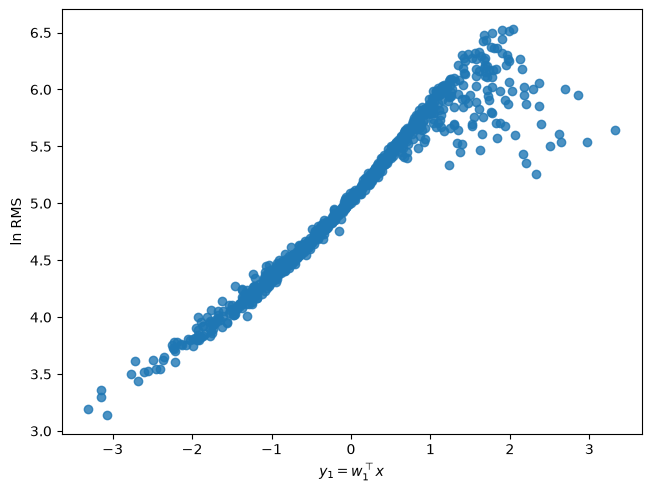

In [11]:
sub_log = ac.active_subspace(space=space7, X=Z[:, :7], f=np.log(rms), grads=d_rms / rms[:, None], estimator='as',
                             n=1, nboot=500, rng=SEED)
sub_log = ac.orient(sub_log, by='covariance', X=Z[:, :7], f=np.log(rms))
ll = sub_log.eigenvalues
print('eigenvalues:', np.array2string(ll, precision=4))
print(f'lambda_1/lambda_2 = {ll[0] / ll[1]:.1f}, lambda_2/lambda_3 = {ll[1] / ll[2]:.1f}; '
      f'|w1(ln RMS) . w1(RMS)| = {abs(sub_log.W[:, 0] @ W[:, 0]):.4f}, |w1(ln RMS) . t| = {abs(sub_log.W[:, 0] @ t):.4f}')
fig, ax = ac.plotting.plot_sufficient_summary(sub_log, X=Z[:, :7], f=np.log(rms), dims=1, qoi_label='ln RMS')
plt.close(fig)
fig

For $\ln\mathrm{RMS}$ the eigenvalues are $0.4653$, $0.01329$ and $1.03\times10^{-3}$, so $\lambda_1/\lambda_2 = 35.0$ and $\lambda_2/\lambda_3 = 12.9$: one dominant direction, the same as for RMS ($|\mathbf w_1^{\ln}\cdot\mathbf w_1| = 0.9991$, overlap with the detuning direction 0.9562). The log response is nearly linear in $y_1$ up to the tuning peak and bends down beyond it; that bend is the second direction's job for RMS itself.

#### The limit-state function

The benchmark's limit state $G = F_s - 3k_s\,\mathrm{RMS}$ has eight inputs. With the same space construction, one more input ($\ln F_s$), and the exact gradient from the files:

eigenvalues: [1.6299e+01 3.6682e+00 4.3753e-01 3.5284e-02 4.4047e-03 1.3010e-03
 2.6268e-31 7.4548e-32]
n = 1 (library "evg" rule); ratios lambda_k/lambda_k+1, k = 1..5: [ 4.44  8.38 12.4   8.01  3.39]
bootstrap mean subspace distance, k = 1..7: [1.443e-02 1.729e-02 1.415e-02 2.294e-02 3.399e-02 1.765e-15 6.047e-01]
w1: mp +0.230, ms -0.319, kp -0.496, ks +0.437, zeta_p +0.171, zeta_s +0.154, S0 -0.060, Fs +0.593
w2: mp -0.225, ms +0.130, kp +0.390, ks -0.453, zeta_p +0.190, zeta_s +0.191, S0 -0.063, Fs +0.706


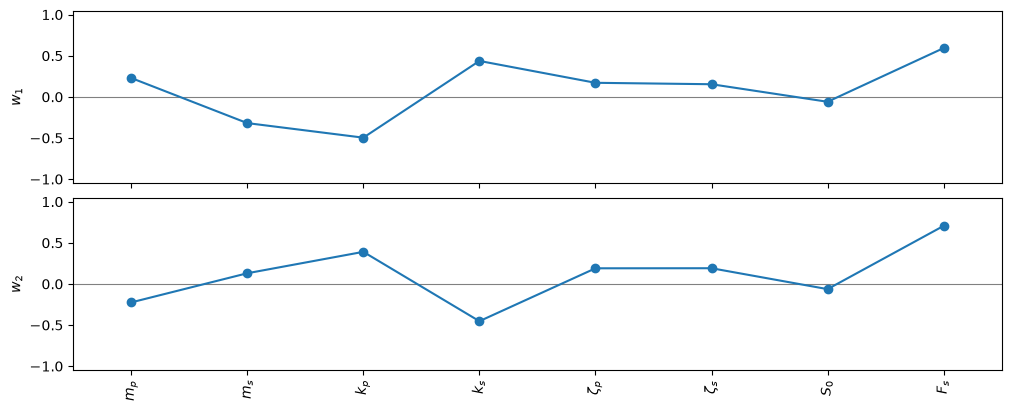

In [12]:
space8 = ac.Gaussian(om.MU, om.SIGMA**2, names=[f'ln {n}' for n in om.NAMES])
sub_G = ac.active_subspace(space=space8, X=Z, f=G, grads=d_G, estimator='as', nboot=500, rng=SEED)
sub_G = ac.orient(sub_G, by='covariance', X=Z, f=G)
lg = sub_G.eigenvalues
print('eigenvalues:', np.array2string(lg, precision=4))
print(f'n = {sub_G.n} (library "evg" rule); ratios lambda_k/lambda_k+1, k = 1..5: '
      f'{np.array2string(lg[:5] / lg[1:6], precision=2)}')
print('bootstrap mean subspace distance, k = 1..7:', np.array2string(sub_G.bootstrap_distances.mean(axis=0), precision=3))
for k in (0, 1):
    print(f'w{k + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(om.NAMES, sub_G.W[:, k])))
fig, axes = ac.plotting.plot_eigenvectors(sub_G, indices=[0, 1], labels=labels8, figsize=(10, 4))
plt.close(fig)
fig

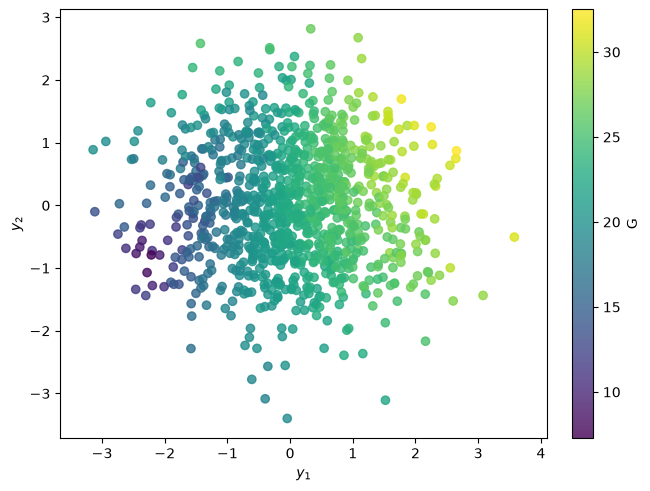

In [13]:
fig, ax = ac.plotting.plot_sufficient_summary(sub_G, X=Z, f=G, dims=2, qoi_label='G')
plt.close(fig)
fig

For $G$ the eigenvalues are 16.30, 3.668, 0.4375, 0.0353, $4.4\times10^{-3}$ and $1.3\times10^{-3}$, with ratios 4.44, 8.38, 12.4, 8.01 and 3.39, and two more at rounding level ($\sim10^{-31}$). The two null directions are again exact: scaling both masses by $c^{-2}$ and $S_0$ by $c^3$, or both stiffnesses by $c^2$ and $S_0$ by $c^{-1}$, leaves $k_s\,\mathrm{RMS}$ unchanged. The gaps are weaker than for RMS; the library rule picks $n = 1$, and the bootstrap distances for $k = 1, 2, 3$ (0.014, 0.017, 0.014) are all small. Both leading eigenvectors combine the capacity $F_s$ ($+0.593$, $+0.706$) with the detuning direction ($k_p$ $-0.496$ / $+0.390$, $k_s$ $+0.437$ / $-0.453$), with opposite signs on the detuning, so together they span roughly "capacity" and "detuning"; the damping ratios have weights below 0.2 in both. $G$ is smallest at the lower left of the two-dimensional plot (low capacity, near tuning); no sample fails (the smallest $G$ is 7.293).

#### Surrogates on the active variables

Polynomials in the active variables, with leave-one-out $R^2$: cubics in one and in two active variables for RMS, a line and a cubic in one variable for $\ln\mathrm{RMS}$, and a cubic in two variables for $G$.

RMS, cubic in y1           LOO R^2 = 0.8451
RMS, cubic in (y1, y2)     LOO R^2 = 0.9116
ln RMS, line in y1         LOO R^2 = 0.9319
ln RMS, cubic in y1        LOO R^2 = 0.9676
G, cubic in (y1, y2)       LOO R^2 = 0.9376


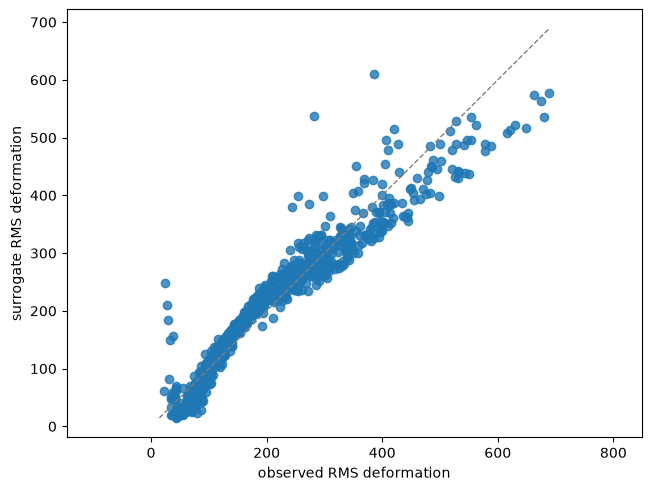

In [14]:
sub1 = ac.active_subspace(space=space7, X=Z[:, :7], f=rms, grads=d_rms, estimator='as', n=1)    # same eigenvectors, n = 1
sub_G2 = ac.active_subspace(space=space8, X=Z, f=G, grads=d_G, estimator='as', n=2)
sur = {
    'RMS, cubic in y1': ac.fit_surrogate(X=Z[:, :7], f=rms, subspace=sub1, kind='poly', degree=3),
    'RMS, cubic in (y1, y2)': ac.fit_surrogate(X=Z[:, :7], f=rms, subspace=sub, kind='poly', degree=3),
    'ln RMS, line in y1': ac.fit_surrogate(X=Z[:, :7], f=np.log(rms), subspace=sub_log, kind='poly', degree=1),
    'ln RMS, cubic in y1': ac.fit_surrogate(X=Z[:, :7], f=np.log(rms), subspace=sub_log, kind='poly', degree=3),
    'G, cubic in (y1, y2)': ac.fit_surrogate(X=Z, f=G, subspace=sub_G2, kind='poly', degree=3),
}
for k, s in sur.items():
    print(f'{k:26s} LOO R^2 = {s.loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur['RMS, cubic in (y1, y2)'], X=Z[:, :7], f=rms, qoi_label='RMS deformation')
plt.close(fig)
fig

Leave-one-out $R^2$: for RMS, 0.8451 with a cubic in $y_1$ and 0.9116 with a cubic in $(y_1, y_2)$; for $\ln\mathrm{RMS}$, 0.9319 with a line and 0.9676 with a cubic in $y_1$; for $G$, 0.9376 with a cubic in $(y_1, y_2)$. The second active variable adds 0.067 to the RMS fit. The figure shows the two-variable RMS cubic; the largest misfits are the largest responses, at the tuning peak, where a cubic cannot follow the sharp resonance.

### Accuracy of Eq. 37, and the paper's Fig. 5

Eq. 37 is a perturbation approximation (small damping and small mass ratio). The files also hold the exact RMS deformation of the secondary spring from a Lyapunov solve of the 2-DOF system of Eq. 1 at every sample. The cell compares the two, and then recomputes the paper's Fig. 5: the amplification factor $E[x_s^2] / (\pi G_0 / 4\zeta_s\omega_s^3)$ against $\beta$ for $\zeta_p = 0.04$, $\zeta_s = 0.02$, $\gamma = 0.01$, from Eq. 37 and from the exact solution, for the spring deformation and for the equipment's displacement relative to the ground. The paper gives the figure only; the "Fig. 5" values were read from the curves of the page image by pixel position (about $\pm 0.2$), not from printed numbers.

Eq. 37 vs exact mean-square spring deformation, 1000 samples: median |rel. error| 0.0137, 1st/99th percentiles -0.0811 / +0.0382, max |rel. error| 0.185
  largest error at a sample with zeta_p = 0.224, zeta_s = 0.0129, beta = -0.135, gamma = 0.0072


Eq. 37 vs exact mean square of the equipment displacement relative to the ground: median |rel. error| 0.377

 beta  Eq. 37  exact, x_s - x_p  exact, x_s  variant  Fig. 5 exact  Fig. 5 matched
 0.00   25.25             25.85       27.75    26.06         25.70            25.2
 0.05   22.75             24.20       24.41    23.68         23.80            22.9
 0.10   16.76             18.08       17.45    17.47         17.50           16.75
 0.15   11.79             12.69       11.89    12.26         12.30        (merged)
 0.20    8.50              9.08        8.37     8.81          8.65        (merged)
 0.25    6.40              6.78        6.20     6.61          6.50        (merged)
largest |exact - Fig. 5 exact| over the six points: x_s - x_p 0.58, x_s 2.05, variant 0.36


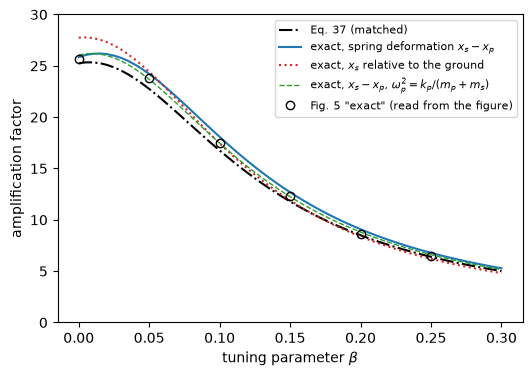

In [15]:
ratio = (rms / rms_exact)**2 - 1                     # relative error of Eq. 37 in the mean square
print(f'Eq. 37 vs exact mean-square spring deformation, 1000 samples: median |rel. error| {np.median(np.abs(ratio)):.4f}, '
      f'1st/99th percentiles {np.percentile(ratio, 1):+.4f} / {np.percentile(ratio, 99):+.4f}, max |rel. error| {np.abs(ratio).max():.3f}')
i_max = np.argmax(np.abs(ratio))
print(f'  largest error at a sample with zeta_p = {X[i_max, 4]:.3f}, zeta_s = {X[i_max, 5]:.4f}, beta = {beta[i_max]:.3f}, '
      f'gamma = {X[i_max, 1] / X[i_max, 0]:.4f}')
ex_s = om.exact_mean_squares(X)
print(f'Eq. 37 vs exact mean square of the equipment displacement relative to the ground: median |rel. error| '
      f'{np.median(np.abs(om.mean_square(X) / ex_s[:, 1] - 1)):.3f}')

zp, zs, gam = 0.04, 0.02, 0.01                         # Fig. 5 parameters
fig5 = {0.0: (25.7, 25.2), 0.05: (23.8, 22.9), 0.1: (17.5, 16.75), 0.15: (12.3, None), 0.2: (8.65, None), 0.25: (6.5, None)}
bb = np.linspace(0, 0.3, 61)
def af(b):
    wp_, ws_ = 1 + b/2, 1 - b/2                        # omega_a = 1; the factor is scale free
    x = np.array([1., gam, wp_**2, gam * ws_**2, zp, zs, 1.])
    base = np.pi / (4 * zs * ws_**3)
    e = om.exact_mean_squares(x)[0]
    x_tot = x.copy(); x_tot[2] *= 1 + gam                   # variant: omega_p^2 = kp/(mp + ms)
    return om.mean_square(x)[0] / base, e[0] / base, e[1] / base, om.exact_mean_squares(x_tot)[0, 0] / base
A5 = np.array([af(b) for b in bb])
print(f"\n{'beta':>5s} {'Eq. 37':>7s} {'exact, x_s - x_p':>17s} {'exact, x_s':>11s} {'variant':>8s} {'Fig. 5 exact':>13s} {'Fig. 5 matched':>15s}")
dev = []
for b, (fe, fm) in fig5.items():
    a = af(b)
    dev.append(np.array(a[1:]) - fe)
    print(f'{b:5.2f} {a[0]:7.2f} {a[1]:17.2f} {a[2]:11.2f} {a[3]:8.2f} {fe:13.2f} {fm if fm else "(merged)":>15}')
print('largest |exact - Fig. 5 exact| over the six points: x_s - x_p {:.2f}, x_s {:.2f}, variant {:.2f}'.format(*np.abs(dev).max(axis=0)))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(bb, A5[:, 0], 'k-.', label='Eq. 37 (matched)')
ax.plot(bb, A5[:, 1], 'C0-', label=r'exact, spring deformation $x_s - x_p$')
ax.plot(bb, A5[:, 2], 'C3:', label=r'exact, $x_s$ relative to the ground')
ax.plot(bb, A5[:, 3], 'C2--', lw=1, label=r'exact, $x_s - x_p$, $\omega_p^2 = k_p/(m_p+m_s)$')
ax.plot(list(fig5), [v[0] for v in fig5.values()], 'ko', mfc='none', label='Fig. 5 "exact" (read from the figure)')
ax.set_xlabel(r'tuning parameter $\beta$'); ax.set_ylabel('amplification factor'); ax.set_ylim(0, 30); ax.legend(fontsize=8)
plt.close(fig)
fig

Over the 1000 samples, Eq. 37 matches the exact mean-square deformation of the secondary spring with a median relative error of 1.4 % (1st and 99th percentiles $-8.1$ % and $+3.8$ %). The largest error, 18.5 %, is at the sample with the largest primary damping ratio ($\zeta_p = 0.224$), where the small-damping assumption of the perturbation theory is weakest. Against the equipment's displacement relative to the ground, the median error is 37.7 %, so Eq. 37 is the spring deformation, not $x_s$ in the coordinates of Eq. 1.

The table recomputes the paper's Fig. 5. Eq. 37 reproduces the figure's "matched" curve (25.25, 22.75, 16.76 against 25.2, 22.9 and 16.75 read from the figure). The figure's "exact" curve is not exactly either of our two exact solutions: the spring deformation is within 0.58 of it at the six points read and agrees at perfect tuning (25.85 against 25.7), while the ground-relative displacement is 2.05 too high there (27.75); between $\beta = 0.1$ and 0.25 the figure's curve lies between the two. A variant of the spring-deformation solution with the primary frequency defined by the total mass, $\omega_p^2 = k_p/(m_p+m_s)$, is within 0.36 at all six points; the paper does not say how the exact curve (from Ref. 3 of the paper) was parameterized, so this is a guess. None of this changes the data set: the benchmark and the files use Eq. 37 as printed.

### Comparison with the paper

The 1985 paper has no probabilistic study; its numerical results are the curves of Figs. 5–8. The benchmark's reference values are a failure probability (OpenTURNS [[4]][R4], $P_f = 3.78\times10^{-7}$, method not stated) and Monte Carlo moments of the RMS (UQTestFuns [[5]][R5], $10^7$ samples: mean 188.48, variance 14 628). The cell recomputes them: moments by Monte Carlo with $10^6$ samples (seed `SEED`), and $P_f$ by FORM and by importance sampling centred at the FORM design point ($10^6$ samples), using the exact gradient of $G$ in standard normal coordinates.

In [16]:
from scipy.optimize import minimize
from scipy.stats import norm
rng = np.random.default_rng(SEED)
r_mc = om.rms(np.exp(om.MU + om.SIGMA * rng.standard_normal((10**6, 8))))
se_mean = r_mc.std(ddof=1) / np.sqrt(len(r_mc))
se_var = np.sqrt((np.mean((r_mc - r_mc.mean())**4) - r_mc.var()**2) / len(r_mc))
print(f'RMS, 1e6 Monte Carlo samples: mean {r_mc.mean():.2f} +- {1.96 * se_mean:.2f}, '
      f'variance {r_mc.var(ddof=1):.0f} +- {1.96 * se_var:.0f} (95 %)')

x_of_u = lambda u: np.exp(om.MU + om.SIGMA * np.atleast_2d(u))
g_u = lambda u: om.limit_state(x_of_u(u))[0]
dg_u = lambda u: om.grad_log_limit_state(x_of_u(u))[0] * om.SIGMA
res = minimize(lambda u: u @ u, np.ones(8), jac=lambda u: 2*u, method='SLSQP',
               constraints=[{'type': 'eq', 'fun': g_u, 'jac': dg_u}], options={'ftol': 1e-12, 'maxiter': 500})
u_star = res.x
b_form = np.linalg.norm(u_star)
x_star = x_of_u(u_star)[0]
print(f'FORM: converged {res.success}, G(u*) = {g_u(u_star):.1e}, reliability index {b_form:.4f}, Pf = {norm.cdf(-b_form):.3e}; '
      f'design point beta (tuning) = {(np.sqrt(x_star[2]/x_star[0]) - np.sqrt(x_star[3]/x_star[1])) / ((np.sqrt(x_star[2]/x_star[0]) + np.sqrt(x_star[3]/x_star[1])) / 2):.4f}')
V = u_star + rng.standard_normal((10**6, 8))
wts = (om.limit_state(x_of_u(V)) <= 0) * np.exp(-V @ u_star + b_form**2 / 2)
pf, se = wts.mean(), wts.std(ddof=1) / np.sqrt(len(wts))
print(f'importance sampling (1e6 samples at the design point): Pf = {pf:.4e}, 95 % interval [{pf - 1.96*se:.4e}, {pf + 1.96*se:.4e}]; '
      f'FORM / IS = {norm.cdf(-b_form) / pf:.1f}')
alpha = u_star / b_form
print('FORM importance directions alpha = u*/|u*|:', ', '.join(f'{n} {a:+.3f}' for n, a in zip(om.NAMES, alpha)),
      f'\n|alpha . w1(G)| = {abs(alpha @ sub_G.W[:, 0]):.3f}, share of alpha in span(w1(G), w2(G)): {np.linalg.norm(sub_G.W[:, :2].T @ alpha)**2:.3f}')

RMS, 1e6 Monte Carlo samples: mean 188.41 +- 0.24, variance 14575 +- 50 (95 %)
FORM: converged True, G(u*) = -1.4e-14, reliability index 4.4712, Pf = 3.888e-06; design point beta (tuning) = -0.0012


importance sampling (1e6 samples at the design point): Pf = 3.8126e-07, 95 % interval [3.7682e-07, 3.8569e-07]; FORM / IS = 10.2
FORM importance directions alpha = u*/|u*|: mp +0.067, ms +0.272, kp +0.288, ks -0.064, zeta_p -0.640, zeta_s -0.412, S0 +0.226, Fs -0.452 
|alpha . w1(G)| = 0.697, share of alpha in span(w1(G), w2(G)): 0.624


| Quantity | Paper or benchmark value | Notebook value |
|---|---|---|
| Amplification factor from Eq. 37, $\zeta_p = 0.04$, $\zeta_s = 0.02$, $\gamma = 0.01$, at $\beta = 0, 0.05, 0.1$ | 25.2, 22.9, 16.75 (read from Fig. 5, "matched", by pixel position, about ±0.2) [1] | 25.25, 22.75, 16.76 |
| Exact amplification factor at $\beta = 0, 0.1, 0.2$ | 25.7, 17.5, 8.65 (read from Fig. 5, "exact", about ±0.2) [1] | spring deformation 25.85, 18.08, 9.08; relative to the ground 27.75, 17.45, 8.37 |
| Mean of RMS | 188.48 (Monte Carlo, $10^7$) [5] | $188.41 \pm 0.24$ ($10^6$ samples); 189.09 (the 1000 in the files) |
| Variance of RMS | 14 628 (Monte Carlo, $10^7$) [5] | $14\,575 \pm 50$ ($10^6$ samples); 15 697 (the 1000) |
| Failure probability $P(G \le 0)$ | $3.78\times10^{-7}$ (method not stated) [4] | $3.81\times10^{-7}$, 95 % interval $[3.77, 3.86]\times10^{-7}$ (importance sampling); FORM $3.89\times10^{-6}$ |
| Active subspace | not reported | RMS: $n = 2$, $\lambda_1/\lambda_2 = 12.1$, $\lambda_2/\lambda_3 = 29.4$; $G$: $\lambda_1/\lambda_2 = 4.44$ |

The mean of RMS agrees with UQTestFuns within our interval; our variance is 53 below theirs, about two of our standard errors (their own $10^6$-sample value, 14 596, is inside our interval), which we attribute to Monte Carlo error in a variance of a heavy-tailed output. Importance sampling gives $P_f = 3.81\times10^{-7}$, and OpenTURNS' $3.78\times10^{-7}$ lies inside its 95 % interval; this confirms that our model, distributions and limit state are the benchmark's. FORM is 10.2 times too high here, because the failure domain is a curved region around perfect tuning: the FORM design point has $\beta = -0.0012$. Its importance directions put most weight on the damping ratios ($\zeta_p$ $-0.640$, $\zeta_s$ $-0.412$) and the capacity ($-0.452$); they overlap the first active direction of $G$ by only 0.697, and 62.4 % of $\boldsymbol\alpha$ lies in the span of the first two. The active subspace describes where $G$ varies on average over the input distribution; the failure point is far in the tail (reliability index 4.47), where low damping at tuning matters most. The 1985 paper reports no sampling study and no subspace.

### References

[1] T. Igusa and A. Der Kiureghian. [Dynamic characterization of two-degree-of-freedom equipment-structure systems](https://doi.org/10.1061/(ASCE)0733-9399(1985)111:1(1)). *Journal of Engineering Mechanics*, 111(1):1–19, 1985.

[2] A. Der Kiureghian and M. De Stefano. [Efficient algorithm for second-order reliability analysis](https://doi.org/10.1061/(ASCE)0733-9399(1991)117:12(2904)). *Journal of Engineering Mechanics*, 117(12):2904–2923, 1991. (Not read for this notebook; cited because OpenTURNS [4] and UQTestFuns [5] attribute the input distributions to it.)

[3] V. Dubourg, B. Sudret, and F. Deheeger. [Metamodel-based importance sampling for structural reliability analysis](https://doi.org/10.1016/j.probengmech.2013.02.002). *Probabilistic Engineering Mechanics*, 33:47–57, 2013. (Not read; cited by OpenTURNS [4] for this benchmark.)

[4] OpenTURNS. "The two-degree-of-freedom primary/secondary damped oscillator model", use case documentation, <https://openturns.github.io/openturns/latest/usecases/use_case_oscillator.html> (accessed 2026-10-30).

[5] D. Wicaksono and M. Hecht. UQTestFuns: A Python3 library of uncertainty quantification (UQ) test functions. *Journal of Open Source Software*, 8(90):5671, 2023. https://doi.org/10.21105/joss.05671. Damped oscillator page: <https://uqtestfuns.readthedocs.io/en/latest/test-functions/damped-oscillator.html> (accessed 2026-10-30).

[6] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.1061/(ASCE)0733-9399(1985)111:1(1)
[R2]: https://doi.org/10.1061/(ASCE)0733-9399(1991)117:12(2904)
[R3]: https://doi.org/10.1016/j.probengmech.2013.02.002
[R4]: https://openturns.github.io/openturns/latest/usecases/use_case_oscillator.html
[R5]: https://doi.org/10.21105/joss.05671

### Acknowledgments

From [[1]][R1]: "This research work is sponsored by the National Science Foundation under Grant No. CEE-8217800, which support is gratefully acknowledged."

In [17]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 10.8 s
